# Autonomous Institutional Reputation Pipeline - Compute-then-Communicate

Run every cell in order (Shift+Enter). Each cell performs one stage.

1. **COMPUTE (pandas + scikit-learn)** - aggregations, rankings, trends, YoY deltas,
   domestic/international splits, KMeans clustering. **No raw rows ever go to the LLM.**
2. **COMMUNICATE** - aggregates-only summary -> local `llama3.1:latest` via Ollama.
3. **ARTIFACTS** - charts + text under `C:/Python/Reputaion/results/`.
4. **EXCEL REPORT** - raw data + Power Pivot dim/fact tabs + charts under
   `C:/Python/Reputaion/reports/`.

## Prerequisites
`pandas`, `numpy`, `scikit-learn`, `matplotlib`, `openpyxl`. For LLM:
`ollama serve` and `ollama pull llama3.1:latest`.

---


## 0. Setup - imports, paths, output folders, chart style

Imports libraries, defines paths, creates `results/` and `reports/` folders,
configures matplotlib `Agg` backend, stores Ollama settings. No data compute here.


In [ ]:
import os
import json
import textwrap
import urllib.request

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# --- Load environment variables from .env ---
ENV_PATH = r"C:\\Python\\AI-DataSuite\\.env"
if os.path.exists(ENV_PATH):
    with open(ENV_PATH, "r", encoding="utf-8") as _env_file:
        for _raw_line in _env_file:
            _line = _raw_line.strip()
            if not _line or _line.startswith("#") or "=" not in _line:
                continue
            _key, _val = _line.split("=", 1)
            _key = _key.strip()
            _val = _val.strip().strip('"').strip("'")
            if _key not in os.environ:
                os.environ[_key] = _val

BASE_DIR = os.getenv("BASE_DIR", r"C:/Python/Reputaion")
CSV_FILE_NAME = os.getenv("CSV_FILE_NAME", "Reputationdata.csv")
CSV_PATH = os.path.join(BASE_DIR, CSV_FILE_NAME)
RESULTS_DIR = os.getenv("RESULTS_DIR", os.path.join(BASE_DIR, "results"))
REPORTS_DIR = os.getenv("REPORTS_DIR", os.path.join(BASE_DIR, "reports"))
OLLAMA_URL = os.getenv("OLLAMA_URL", "http://localhost:11434/api/chat")
OLLAMA_MODEL = os.getenv("OLLAMA_MODEL", "llama3.1:latest")

os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(REPORTS_DIR, exist_ok=True)

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "axes.grid": True,
    "grid.alpha": 0.3,
    "figure.dpi": 150,
    "savefig.bbox": "tight",
})

print("Setup complete.")
print("  Base dir:   ", BASE_DIR)
print("  CSV path:   ", CSV_PATH)
print("  Results dir:", RESULTS_DIR)
print("  Reports dir:", REPORTS_DIR)
print("  Ollama URL: ", OLLAMA_URL)
print("  Ollama model:", OLLAMA_MODEL)


## 1. Load and clean the data

Reads `Reputationdata.csv` into `df`, normalizes column names (fixes trailing space
in `Year `), runs validation checks, saves cleaned copy to
`results/reputation_clean.csv`. Raw rows stay local - never sent to LLM.


In [2]:
df = pd.read_csv(CSV_PATH)
df.columns = [c.strip() for c in df.columns]

print("Shape (rows, columns):", df.shape)
print("\nColumns:", list(df.columns))
print("\nData types:\n", df.dtypes)
print("\nMissing values per column:\n", df.isna().sum())
print("\nYears:", sorted(df["Year"].dropna().unique()))
print("Reputation types:", df["Type"].unique())
print("Subjects:", df["Subject"].nunique())
print("Voter locations:", df["Voter Location"].nunique())
print("Domestic/International flag:", df["Domestic/intern Votes"].unique())
print("\nFirst 5 rows:\n", df.head())

df.to_csv(os.path.join(RESULTS_DIR, "reputation_clean.csv"), index=False)
print("\nCleaned data saved to results/reputation_clean.csv")


Shape (rows, columns): (16734, 7)

Columns: ['Subject', 'Institution', 'Voter Location', 'Type', 'Votes', 'Year', 'Domestic/intern Votes']

Data types:
 Subject                  object
Institution              object
Voter Location           object
Type                     object
Votes                     int64
Year                      int64
Domestic/intern Votes    object
dtype: object

Missing values per column:
 Subject                  0
Institution              0
Voter Location           0
Type                     0
Votes                    0
Year                     0
Domestic/intern Votes    0
dtype: int64

Years: [2021, 2022, 2023, 2024]
Reputation types: ['Research reputation (unweighted)' 'Teaching reputation (unweighted)']
Subjects: 11
Voter locations: 23
Domestic/International flag: ['InternationalVotes' 'DomesticVotes']

First 5 rows:
            Subject                         Institution Voter Location  \
0  Social Sciences    Arizona State University (Tempe)  All of Af

## 2. COMPUTE - Aggregations and Rankings

Sums `Votes` by Institution x Type x Year and by Institution x Year. Produces
top-10 tables (overall, Research, Teaching, 2024). Saved as CSV artifacts.


In [5]:
def sum_votes(group_cols):
    return (df.groupby(group_cols, as_index=False)["Votes"]
              .sum()
              .rename(columns={"Votes": "Total Votes"}))

agg_inst_type_year = sum_votes(["Institution", "Type", "Year"])
agg_inst_year = sum_votes(["Institution", "Year"])
agg_inst_total = (df.groupby("Institution", as_index=False)["Votes"]
                  .sum()
                  .rename(columns={"Votes": "Total Votes"})
                  .sort_values("Total Votes", ascending=False))
agg_inst_type = sum_votes(["Institution", "Type"])

top10_overall = agg_inst_total.head(10)
top10_research = (agg_inst_type[agg_inst_type["Type"] == "Research reputation (unweighted)"]
                  .sort_values("Total Votes", ascending=False).head(10))
top10_teaching = (agg_inst_type[agg_inst_type["Type"] == "Teaching reputation (unweighted)"]
                  .sort_values("Total Votes", ascending=False).head(10))
top10_2024 = (agg_inst_year[agg_inst_year["Year"] == 2024]
              .sort_values("Total Votes", ascending=False).head(10))

print("=== Top 10 institutions overall ===")
print(top10_overall.to_string(index=False))
print("\n=== Top 10 - Research ===")
print(top10_research.to_string(index=False))
print("\n=== Top 10 - Teaching ===")
print(top10_teaching.to_string(index=False))
print("\n=== Top 10 - 2024 ===")
print(top10_2024.to_string(index=False))

agg_inst_type_year.to_csv(os.path.join(RESULTS_DIR, "agg_institution_type_year.csv"), index=False)
agg_inst_year.to_csv(os.path.join(RESULTS_DIR, "agg_institution_year.csv"), index=False)
agg_inst_total.to_csv(os.path.join(RESULTS_DIR, "agg_institution_total.csv"), index=False)
print("\nAggregation tables saved to results/")


=== Top 10 institutions overall ===
                       Institution  Total Votes
    University of British Columbia         7685
                 McGill University         6078
               Sorbonne University         5050
                  Fudan University         2556
             University of Alberta         2435
   Queen Mary University of London         2396
Autonomous University of Barcelona         2302
            University of Montreal         2199
             University of Arizona         2085
            University of Tübingen         2046

=== Top 10 - Research ===
                       Institution                             Type  Total Votes
    University of British Columbia Research reputation (unweighted)         4683
                 McGill University Research reputation (unweighted)         3667
               Sorbonne University Research reputation (unweighted)         2958
   Queen Mary University of London Research reputation (unweighted)         1492
    

## 3. COMPUTE - Trends and Year-over-Year (YoY) Deltas

Builds Institution x Year pivot, computes YoY vote/percent deltas per year pair
with Rising/Declining/Stable labels, plus overall volume table. Saved as CSV.


In [6]:
pivot_year = (agg_inst_year.pivot(index="Institution", columns="Year", values="Total Votes")
              .fillna(0))

years = sorted(pivot_year.columns)
print("Years available:", years)

yoy_frames = []
for i in range(1, len(years)):
    prev, curr = years[i-1], years[i]
    tmp = pd.DataFrame({
        "Institution": pivot_year.index,
        f"Votes {prev}": pivot_year[prev].values,
        f"Votes {curr}": pivot_year[curr].values,
    })
    tmp["YoY Delta (votes)"] = tmp[f"Votes {curr}"] - tmp[f"Votes {prev}"]
    tmp["YoY Delta (%)"] = np.where(tmp[f"Votes {prev}"] > 0,
                                   100.0 * tmp["YoY Delta (votes)"] / tmp[f"Votes {prev}"],
                                   np.nan)
    def trend_label(v):
        if pd.isna(v):
            return "No prior data"
        if v > 5:
            return "Rising"
        if v < -5:
            return "Declining"
        return "Stable"
    tmp["Trend"] = tmp["YoY Delta (%)"].apply(trend_label)
    tmp["Year Pair"] = f"{prev} -> {curr}"
    yoy_frames.append(tmp)

yoy = pd.concat(yoy_frames, ignore_index=True)

yoy_overall = (agg_inst_year.groupby("Year")["Total Votes"].sum()
               .reset_index().sort_values("Year"))
yoy_overall["YoY Delta (votes)"] = yoy_overall["Total Votes"].diff()
yoy_overall["YoY Delta (%)"] = yoy_overall["Total Votes"].pct_change() * 100

print("=== Overall vote volume by year ===")
print(yoy_overall.to_string(index=False))
print("\n=== Biggest risers (2023 -> 2024) ===")
print(yoy[yoy["Year Pair"] == "2023 -> 2024"]
      .sort_values("YoY Delta (votes)", ascending=False).head(10)
      .to_string(index=False))
print("\n=== Biggest fallers (2023 -> 2024) ===")
print(yoy[yoy["Year Pair"] == "2023 -> 2024"]
      .sort_values("YoY Delta (votes)").head(10)
      .to_string(index=False))

yoy.to_csv(os.path.join(RESULTS_DIR, "yoy_deltas.csv"), index=False)
yoy_overall.to_csv(os.path.join(RESULTS_DIR, "yoy_overall.csv"), index=False)
print("\nYoY tables saved to results/")


Years available: [2021, 2022, 2023, 2024]
=== Overall vote volume by year ===
 Year  Total Votes  YoY Delta (votes)  YoY Delta (%)
 2021         4394                NaN            NaN
 2022        12257             7863.0     178.948566
 2023        15146             2889.0      23.570205
 2024        21772             6626.0      43.747524

=== Biggest risers (2023 -> 2024) ===
                       Institution  Votes 2021  Votes 2022  YoY Delta (votes)  YoY Delta (%)  Trend    Year Pair  Votes 2023  Votes 2024
    University of British Columbia         NaN         NaN                987      45.006840 Rising 2023 -> 2024      2193.0      3180.0
                 McGill University         NaN         NaN                708      40.854010 Rising 2023 -> 2024      1733.0      2441.0
               Sorbonne University         NaN         NaN                668      48.937729 Rising 2023 -> 2024      1365.0      2033.0
            University of Auckland         NaN         NaN            

## 4. COMPUTE - Domestic vs International Split

Splits votes by institution into DomesticVotes / InternationalVotes with share
percentages, plus Type x Domestic/International totals table. Saved to CSV.


In [7]:
di = (df.groupby(["Institution", "Domestic/intern Votes"], as_index=False)["Votes"]
      .sum().rename(columns={"Votes": "Votes"}))

di_pivot = di.pivot(index="Institution", columns="Domestic/intern Votes", values="Votes").fillna(0)
di_pivot["Total Votes"] = di_pivot.sum(axis=1)
di_pivot["Domestic Share (%)"] = 100.0 * di_pivot["DomesticVotes"] / di_pivot["Total Votes"]
di_pivot["International Share (%)"] = 100.0 * di_pivot["InternationalVotes"] / di_pivot["Total Votes"]
di_pivot = di_pivot.sort_values("Total Votes", ascending=False)

print("=== Domestic / International split (top 15) ===")
print(di_pivot.head(15).round(1).to_string())

di_type = (df.groupby(["Type", "Domestic/intern Votes"], as_index=False)["Votes"]
           .sum().rename(columns={"Votes": "Votes"}))
print("\n=== Votes by type x domestic/international ===")
print(di_type.pivot(index="Type", columns="Domestic/intern Votes", values="Votes").to_string())

di_pivot.to_csv(os.path.join(RESULTS_DIR, "domestic_international_split.csv"))
print("\nDomestic/international split saved to results/")


=== Domestic / International split (top 15) ===
Domestic/intern Votes                DomesticVotes  InternationalVotes  Total Votes  Domestic Share (%)  International Share (%)
Institution                                                                                                                     
University of British Columbia                1434                6251         7685                18.7                     81.3
McGill University                             1223                4855         6078                20.1                     79.9
Sorbonne University                            106                4944         5050                 2.1                     97.9
Fudan University                                21                2535         2556                 0.8                     99.2
University of Alberta                          521                1914         2435                21.4                     78.6
Queen Mary University of London                 5

## 5. COMPUTE - KMeans Clustering (Peer Groups)

One row per institution with scaled features. Picks k via silhouette score,
fits KMeans, labels each institution with peer group. Aggregates only.


In [8]:
feat = agg_inst_total.copy()

rt = agg_inst_type.pivot(index="Institution", columns="Type", values="Total Votes").fillna(0)
rt.columns = ["Research Votes", "Teaching Votes"]
feat = feat.merge(rt, on="Institution", how="left")

feat = feat.merge(di_pivot[["Domestic Share (%)", "International Share (%)"]],
                  left_on="Institution", right_index=True, how="left")

first_year = pivot_year.columns.min()
last_year = pivot_year.columns.max()
yoy_growth = 100.0 * (pivot_year[last_year] - pivot_year[first_year]) / pivot_year[first_year].replace(0, np.nan)
feat["YoY Growth first->last (%)"] = yoy_growth.reindex(feat["Institution"]).values

subj_div = df.groupby("Institution")["Subject"].nunique().rename("Subjects Rated")
feat = feat.merge(subj_div, on="Institution", how="left")
feat = feat.fillna(0)

feature_cols = ["Total Votes", "Research Votes", "Teaching Votes",
                "Domestic Share (%)", "International Share (%)",
                "YoY Growth first->last (%)", "Subjects Rated"]
X = feat[feature_cols].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

silhouette = {}
for k in range(2, 7):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    silhouette[k] = silhouette_score(X_scaled, labels)

best_k = max(silhouette, key=silhouette.get)
print("Silhouette scores by k:", {k: round(v, 3) for k, v in silhouette.items()})
print("Selected k (best silhouette):", best_k)

kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
feat["Cluster"] = kmeans.fit_predict(X_scaled)

profile = feat.groupby("Cluster")[feature_cols].mean().round(2)

print("\n=== Cluster profiles ===")
print(profile.to_string())
print("\n=== Institutions per cluster ===")
print(feat.groupby("Cluster")["Institution"].apply(list).to_string())

feat.to_csv(os.path.join(RESULTS_DIR, "institution_clusters.csv"), index=False)
profile.to_csv(os.path.join(RESULTS_DIR, "cluster_profiles.csv"))
print("\nCluster assignments saved to results/institution_clusters.csv")


Silhouette scores by k: {2: 0.522, 3: 0.474, 4: 0.456, 5: 0.436, 6: 0.379}
Selected k (best silhouette): 2

=== Cluster profiles ===
         Total Votes  Research Votes  Teaching Votes  Domestic Share (%)  International Share (%)  YoY Growth first->last (%)  Subjects Rated
Cluster                                                                                                                                      
0            1579.82          949.50          630.32               10.77                    89.23                      446.72            11.0
1            6271.00         3769.33         2501.67               13.63                    86.37                      414.63            11.0

=== Institutions per cluster ===
Cluster
0    [Fudan University, University of Alberta, Quee...
1    [University of British Columbia, McGill Univer...

Cluster assignments saved to results/institution_clusters.csv


## 6. ARTIFACTS - Charts  <-- RUN THIS CELL TO SEE CHARTS INLINE

Renders five charts from aggregate tables. Each chart is **displayed inline**
in the cell output (via `display(Image(...))`) and saved as PNG under `results/`.

Charts:
1. `chart_top10_overall.png` - Top 10 institutions by total votes.
2. `chart_yoy_2023_2024.png` - Biggest vote changes 2023 -> 2024.
3. `chart_domestic_international.png` - Domestic vs International share, top 10.
4. `chart_clusters.png` - Peer groups: Research vs Teaching votes.
5. `chart_volume_by_year.png` - Total vote volume by year.

**Important:** Run cells 0-5 first so `top10_overall`, `yoy`, `di_pivot`, `feat`,
and `yoy_overall` are defined, then run this cell.


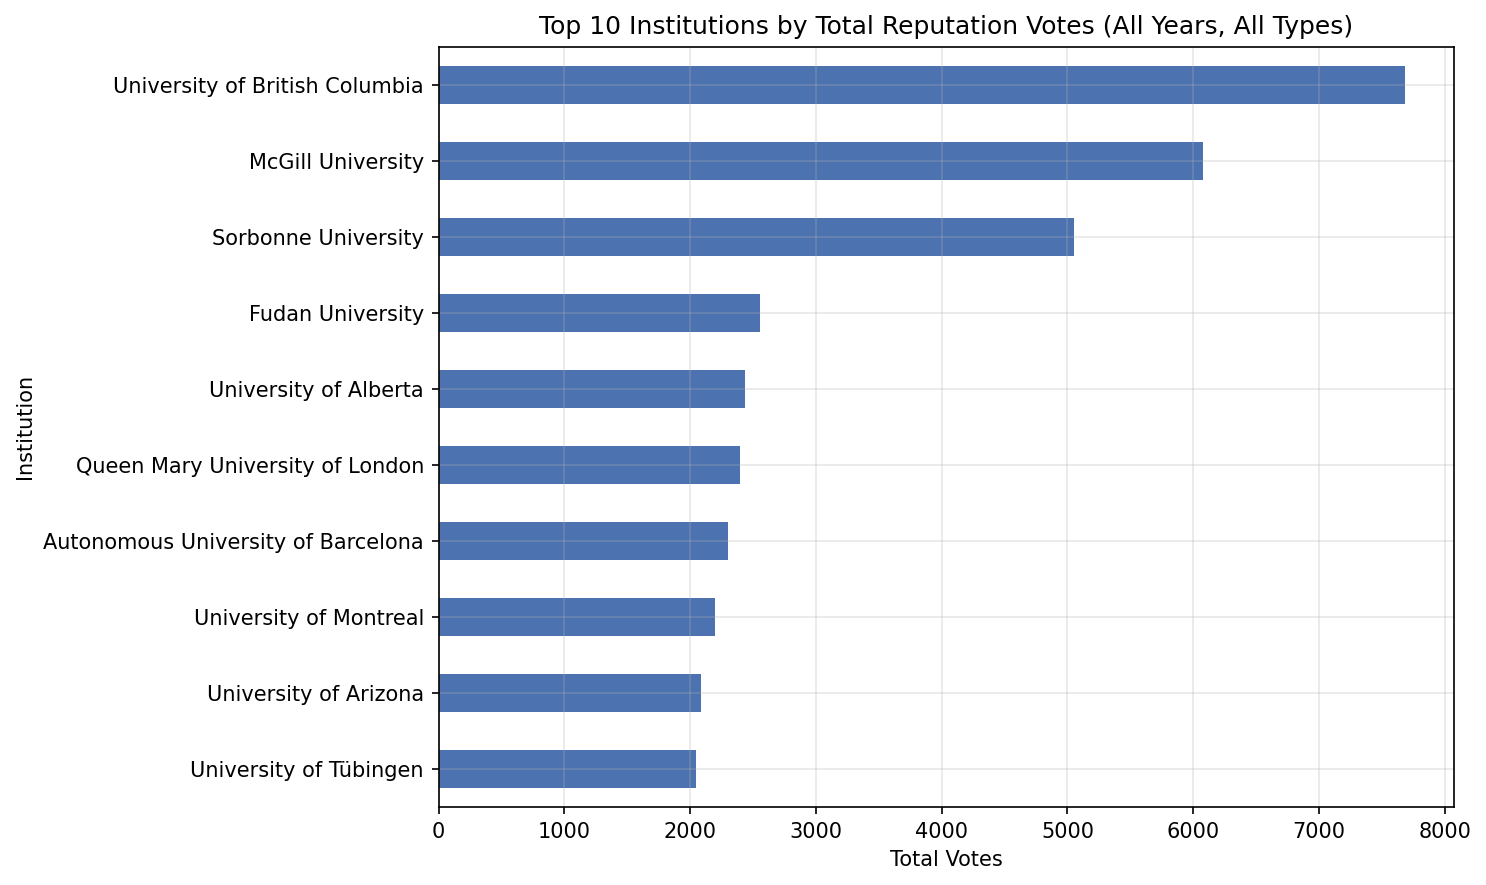

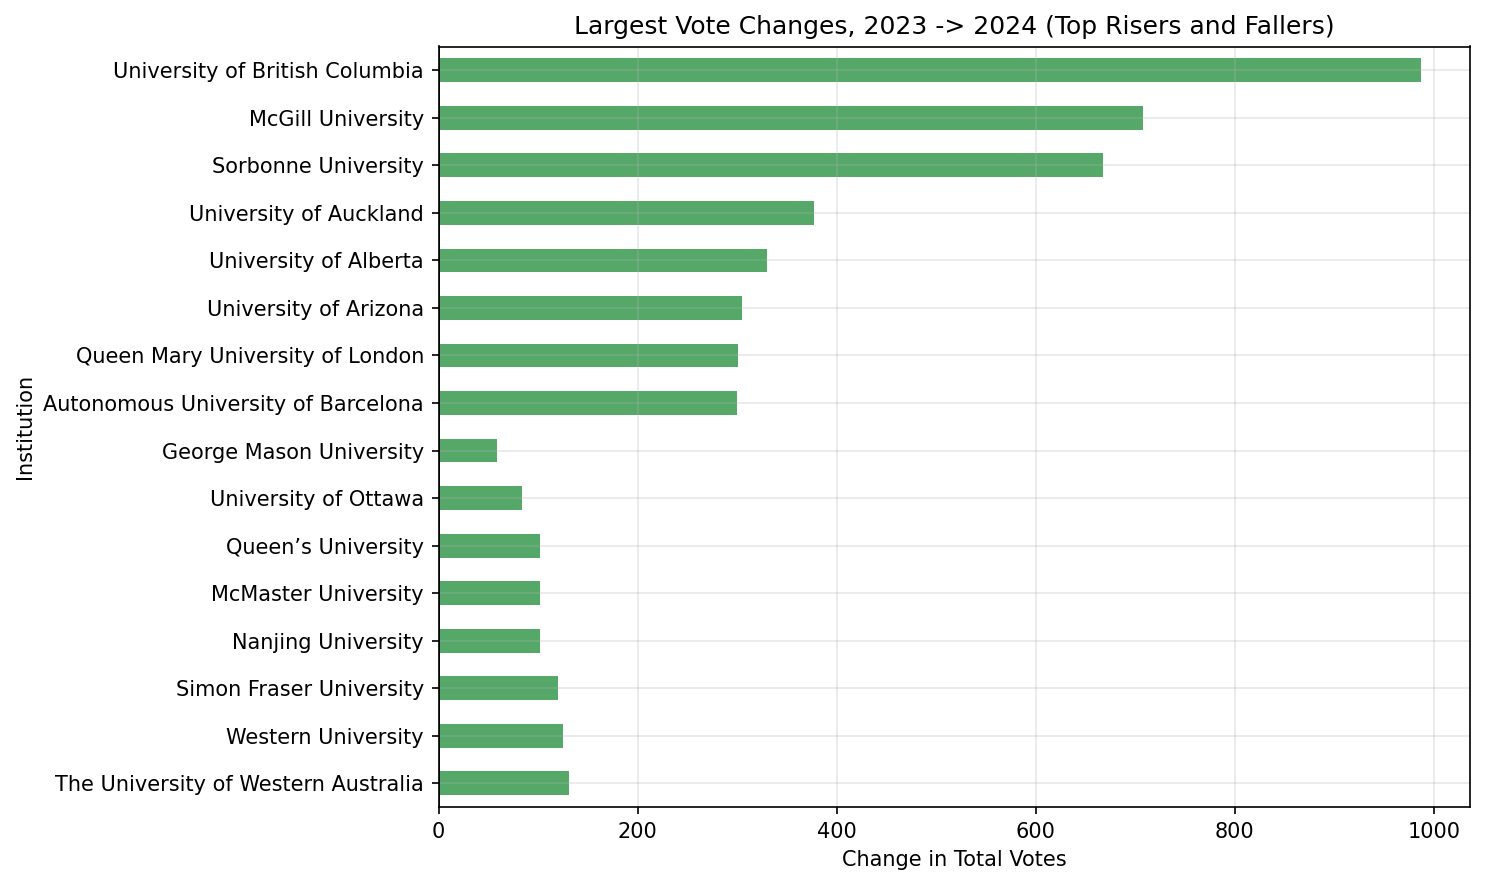

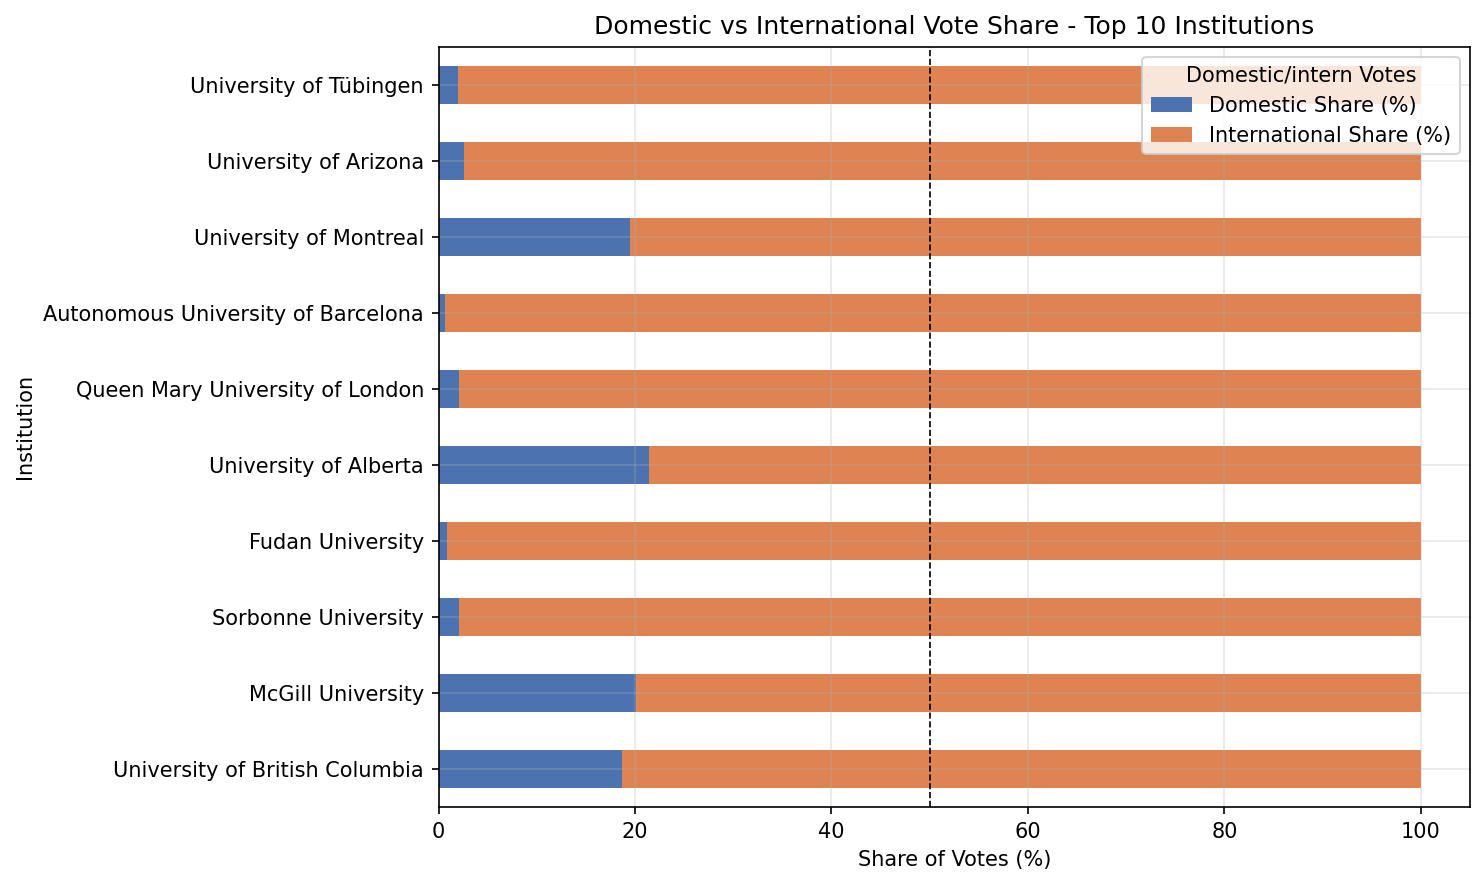

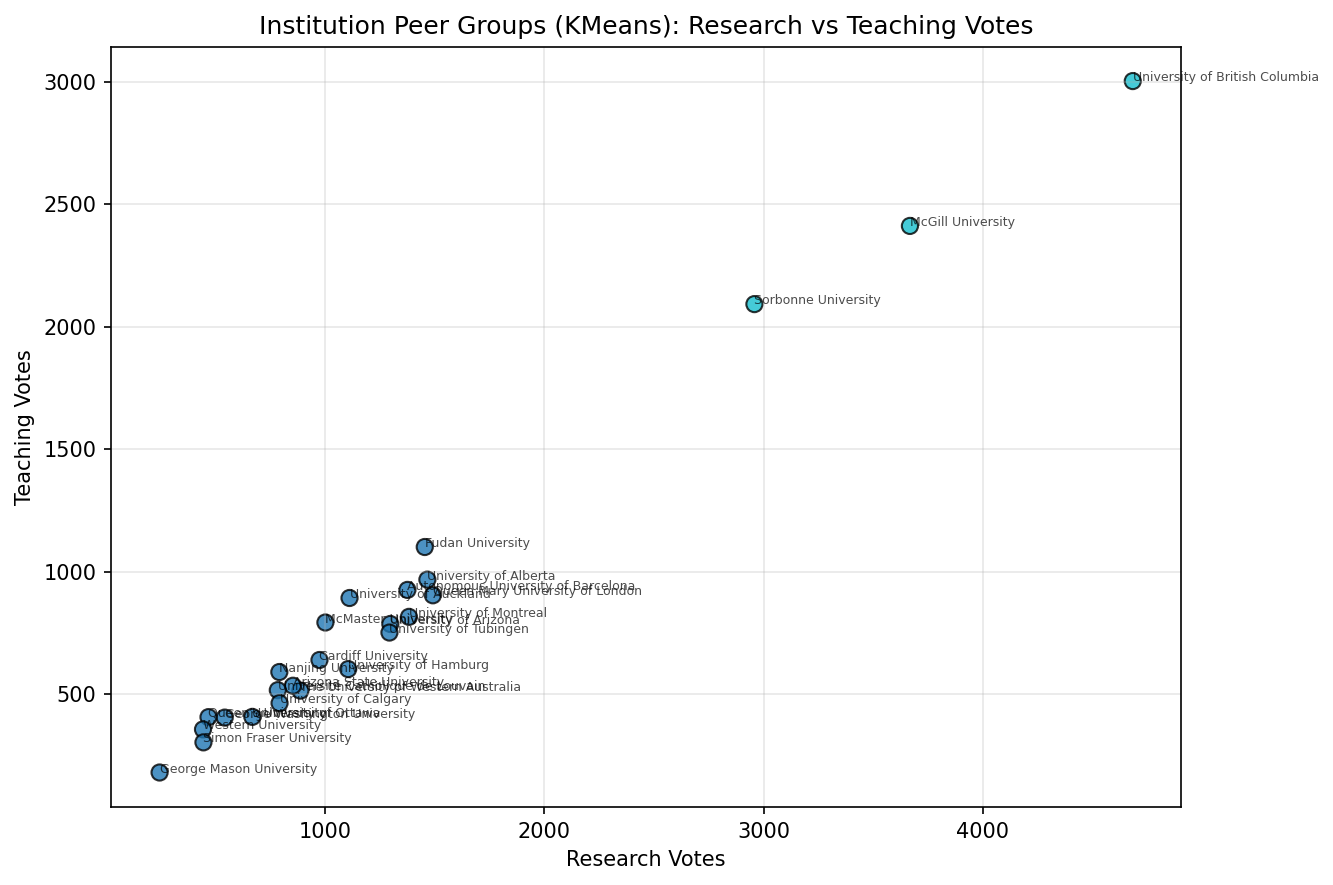

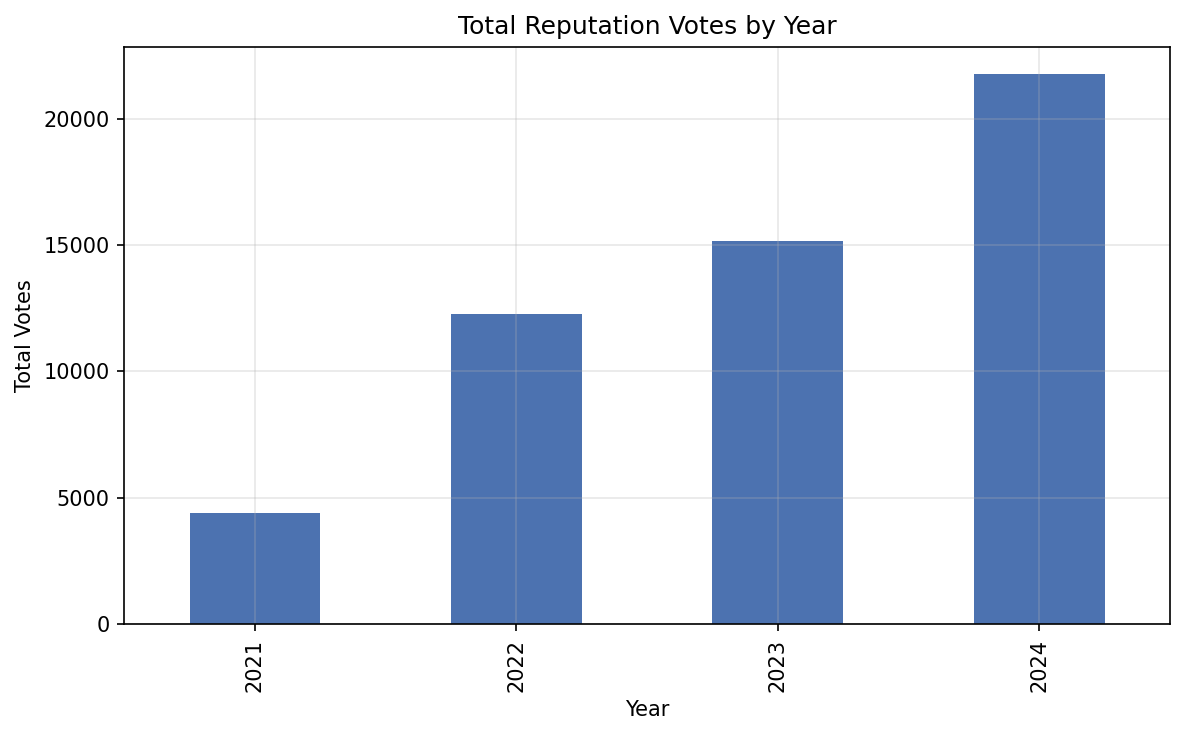

Charts saved to results/:
   chart_cluster_scatter.png
   chart_clusters.png
   chart_domestic_international.png
   chart_research_teaching_by_year.png
   chart_subject_totals.png
   chart_top10_institutions.png
   chart_top10_overall.png
   chart_volume_by_year.png
   chart_year_trend.png
   chart_yoy_2023_2024.png


In [9]:
from io import BytesIO
from IPython.display import display, Image

# Chart 1: Top 10 institutions overall
fig, ax = plt.subplots(figsize=(10, 6))
top10_overall.iloc[::-1].plot(kind="barh", x="Institution", y="Total Votes", ax=ax,
                               color="#4c72b0", legend=False)
ax.set_title("Top 10 Institutions by Total Reputation Votes (All Years, All Types)")
ax.set_xlabel("Total Votes")
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, "chart_top10_overall.png"))
buf = BytesIO(); fig.savefig(buf, format="png", bbox_inches="tight", dpi=150); buf.seek(0)
display(Image(data=buf.read())); plt.close(fig)

# Chart 2: YoY change 2023 -> 2024, top risers & fallers
pair = yoy[yoy["Year Pair"] == "2023 -> 2024"].copy()
top_chg = pd.concat([pair.sort_values("YoY Delta (votes)", ascending=False).head(8),
                     pair.sort_values("YoY Delta (votes)").head(8)])
fig, ax = plt.subplots(figsize=(10, 6))
colors = ["#55a868" if v > 0 else "#c44e52" for v in top_chg["YoY Delta (votes)"]]
top_chg.iloc[::-1].plot(kind="barh", x="Institution", y="YoY Delta (votes)", ax=ax,
                        color=colors, legend=False)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Largest Vote Changes, 2023 -> 2024 (Top Risers and Fallers)")
ax.set_xlabel("Change in Total Votes")
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, "chart_yoy_2023_2024.png"))
buf = BytesIO(); fig.savefig(buf, format="png", bbox_inches="tight", dpi=150); buf.seek(0)
display(Image(data=buf.read())); plt.close(fig)

# Chart 3: Domestic vs International share for top 10 by total votes
top10_inst = set(agg_inst_total.head(10)["Institution"])
di_plot = di_pivot.loc[list(top10_inst)].sort_values("Total Votes").iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 6))
di_plot[["Domestic Share (%)", "International Share (%)"]].plot(kind="barh", stacked=True, ax=ax,
                                                                color=["#4c72b0", "#dd8452"], legend=True)
ax.axvline(50, color="black", linewidth=0.8, linestyle="--")
ax.set_title("Domestic vs International Vote Share - Top 10 Institutions")
ax.set_xlabel("Share of Votes (%)")
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, "chart_domestic_international.png"))
buf = BytesIO(); fig.savefig(buf, format="png", bbox_inches="tight", dpi=150); buf.seek(0)
display(Image(data=buf.read())); plt.close(fig)

# Chart 4: Cluster scatter (Research vs Teaching votes, colored by peer group)
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(feat["Research Votes"], feat["Teaching Votes"],
           c=feat["Cluster"], cmap="tab10", s=60, alpha=0.8, edgecolor="k")
for _, r in feat.iterrows():
    ax.annotate(r["Institution"].split(" (")[0], (r["Research Votes"], r["Teaching Votes"]),
                fontsize=6, alpha=0.7)
ax.set_title("Institution Peer Groups (KMeans): Research vs Teaching Votes")
ax.set_xlabel("Research Votes"); ax.set_ylabel("Teaching Votes")
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, "chart_clusters.png"))
buf = BytesIO(); fig.savefig(buf, format="png", bbox_inches="tight", dpi=150); buf.seek(0)
display(Image(data=buf.read())); plt.close(fig)

# Chart 5: Total vote volume by year
fig, ax = plt.subplots(figsize=(8, 5))
yoy_overall.plot(kind="bar", x="Year", y="Total Votes", ax=ax, color="#4c72b0", legend=False)
ax.set_title("Total Reputation Votes by Year")
ax.set_ylabel("Total Votes")
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, "chart_volume_by_year.png"))
buf = BytesIO(); fig.savefig(buf, format="png", bbox_inches="tight", dpi=150); buf.seek(0)
display(Image(data=buf.read())); plt.close(fig)

print("Charts saved to results/:")
for f in sorted(os.listdir(RESULTS_DIR)):
    if f.endswith(".png"):
        print("  ", f)


## 7. COMMUNICATE - Build the Structured Text Summary

Assembles a plain-text summary of every insight (aggregates only, no raw rows)
and stores it in `summary_text` for the Ollama cell.


In [ ]:
lines = []
lines.append("AUTONOMOUS INSTITUTIONAL REPUTATION PIPELINE - NARRATIVE SUMMARY")
lines.append("=" * 70)
lines.append("")
lines.append(f"Data source: " + CSV_FILE_NAME + f" ({len(df):,} vote records, "
             f"{df['Year'].min()}-{df['Year'].max()})")
lines.append(f"Institutions: {df['Institution'].nunique()} | Subjects: {df['Subject'].nunique()} | "
             f"Voter locations: {df['Voter Location'].nunique()}")
lines.append(f"Reputation types: {', '.join(df['Type'].unique())}")
lines.append("")

lines.append("1. OVERALL VOLUME")
for _, r in yoy_overall.iterrows():
    if pd.notna(r["YoY Delta (%)"]):
        lines.append(f"  {int(r['Year'])}: {r['Total Votes']:,.0f} total votes "
                     f"({r['YoY Delta (%)']:+.1f}% YoY)")
    else:
        lines.append(f"  {int(r['Year'])}: {r['Total Votes']:,.0f} total votes")
lines.append("")

lines.append("2. TOP INSTITUTIONS (ALL YEARS, ALL TYPES)")
lines.append(top10_overall.to_string(index=False))
lines.append("")

lines.append("3. RESEARCH vs TEACHING REPUTATION (top 5 each)")
lines.append("--- Research ---")
lines.append(top10_research.head(5).to_string(index=False))
lines.append("--- Teaching ---")
lines.append(top10_teaching.head(5).to_string(index=False))
lines.append("")

lines.append("4. YEAR-OVER-YEAR MOVERS (2023 -> 2024)")
y24 = yoy[yoy["Year Pair"] == "2023 -> 2024"]
lines.append("Top risers:")
lines.append(y24.sort_values("YoY Delta (votes)", ascending=False).head(5)[
    ["Institution", "YoY Delta (votes)", "YoY Delta (%)", "Trend"]].to_string(index=False))
lines.append("Top fallers:")
lines.append(y24.sort_values("YoY Delta (votes)").head(5)[
    ["Institution", "YoY Delta (votes)", "YoY Delta (%)", "Trend"]].to_string(index=False))
lines.append("")

lines.append("5. DOMESTIC vs INTERNATIONAL (top 10 institutions)")
lines.append(di_pivot.head(10)[["Domestic Share (%)", "International Share (%)"]].round(1).to_string())
lines.append("")

lines.append("6. PEER GROUPS (KMeans clusters)")
lines.append(profile.round(1).to_string())
lines.append("")
for cl in sorted(feat["Cluster"].unique()):
    members = feat.loc[feat["Cluster"] == cl, "Institution"].tolist()
    lines.append(f"Cluster {cl}: {', '.join(members)}")
lines.append("")

lines.append("7. METHOD NOTES")
lines.append("- All figures are vote aggregates (sum of the 'Votes' column).")
lines.append("- YoY delta = change in total votes between consecutive years.")
lines.append("- Clusters built on scaled institution-level features; KMeans k by silhouette score.")
summary_text = "\n".join(lines)
print(summary_text)


## 8. COMMUNICATE - Send the Summary to Ollama (llama3.1:latest)

Wraps `summary_text` in a prompt and sends it to local Ollama chat API
(`http://localhost:11434/api/chat`, model `llama3.1:latest`). Saves narrative to
`results/reputation_narrative.txt`. If Ollama unavailable, writes fallback.


In [ ]:
def build_prompt(summary_text: str) -> str:
    return f"""
You are an expert analyst writing an institutional reputation narrative.
Use ONLY the structured summary below. Do not ask for raw data, and do not
invent institutions or figures.

Write a professional narrative report (Executive Summary, Key Insights,
Trends, Peer Groups, Recommendations) based on this summary:

{summary_text}
""".strip()

prompt = build_prompt(summary_text)

narrative = None
try:
    payload = {
        "model": OLLAMA_MODEL,
        "messages": [{"role": "user", "content": prompt}],
        "stream": False,
        "options": {"temperature": 0.3},
    }
    req = urllib.request.Request(
        OLLAMA_URL,
        data=json.dumps(payload).encode("utf-8"),
        headers={"Content-Type": "application/json"},
        method="POST",
    )
    with urllib.request.urlopen(req, timeout=120) as resp:
        data = json.loads(resp.read().decode("utf-8"))
    narrative = data["message"]["content"]
    print(f"Narrative received from Ollama ({OLLAMA_MODEL}).")
except Exception as e:
    print(f"Ollama not available ({e}). Using local fallback narrative.")
    narrative = textwrap.dedent(f"""
    [LOCAL FALLBACK - Ollama {OLLAMA_MODEL} was not reachable]
    The compute stage produced the structured summary above. To get the LLM
    narrative, start Ollama, ensure the model '{OLLAMA_MODEL}' is pulled
    (`ollama pull {OLLAMA_MODEL}`), then re-run this cell.
    """).strip()

narrative_path = os.path.join(RESULTS_DIR, NARRATIVE_FILE)
with open(narrative_path, "w", encoding="utf-8") as f:
    f.write(narrative)

print("\n=== NARRATIVE (first 1500 chars) ===")
print(narrative[:1500])
print("\nFull narrative saved to:", narrative_path)


## 9. EXCEL REPORT - Power Pivot-ready Workbook

Builds `reports/Reputation_Pipeline_Report.xlsx` with Raw Data + dimension tables
(Dim Year, Dim Institution, Dim Subject, Dim Location, Dim Type) + Fact Reputation
(surrogate keys for Power Pivot) + Cluster Assignments + Cluster Profiles +
Aggregations with embedded chart.


In [ ]:
from openpyxl import Workbook
from openpyxl.chart import BarChart, Reference

excel_path = os.path.join(REPORTS_DIR, EXCEL_FILE)

dim_year = pd.DataFrame({"Year": sorted(df["Year"].unique())})
dim_year["Year Key"] = range(1, len(dim_year) + 1)

dim_institution = agg_inst_total.copy()
dim_institution["Cluster"] = feat["Cluster"].values
dim_institution["Institution Key"] = range(1, len(dim_institution) + 1)
dim_institution = dim_institution[["Institution Key", "Institution", "Total Votes", "Cluster"]]
dim_institution.columns = ["Institution Key", "Institution Name", "Total Votes", "Peer Group (Cluster)"]

dim_subject = pd.DataFrame({"Subject": sorted(df["Subject"].unique())})
dim_subject["Subject Key"] = range(1, len(dim_subject) + 1)
dim_subject = dim_subject[["Subject Key", "Subject"]]

dim_location = pd.DataFrame({"Voter Location": sorted(df["Voter Location"].unique())})
dim_location["Location Key"] = range(1, len(dim_location) + 1)
dim_location = dim_location[["Location Key", "Voter Location"]]

dim_type = pd.DataFrame({"Type": sorted(df["Type"].unique())})
dim_type["Type Key"] = range(1, len(dim_type) + 1)
dim_type = dim_type[["Type Key", "Type"]]

fact = df.merge(dim_year, left_on="Year", right_on="Year")
fact = fact.merge(dim_institution[["Institution Key", "Institution Name"]],
                  left_on="Institution", right_on="Institution Name")
fact = fact.merge(dim_subject, on="Subject")
fact = fact.merge(dim_location, on="Voter Location")
fact = fact.merge(dim_type, on="Type")
fact = fact[["Year Key", "Institution Key", "Subject Key", "Location Key", "Type Key",
             "Domestic/intern Votes", "Votes"]]
fact = fact.rename(columns={"Votes": "Vote Count", "Domestic/intern Votes": "Vote Scope"})
fact.to_csv(os.path.join(RESULTS_DIR, FACT_CSV), index=False)

with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    df.to_excel(writer, sheet_name="Raw Data", index=False)
    dim_year.to_excel(writer, sheet_name="Dim Year", index=False)
    dim_institution.to_excel(writer, sheet_name="Dim Institution", index=False)
    dim_subject.to_excel(writer, sheet_name="Dim Subject", index=False)
    dim_location.to_excel(writer, sheet_name="Dim Location", index=False)
    dim_type.to_excel(writer, sheet_name="Dim Type", index=False)
    fact.to_excel(writer, sheet_name="Fact Reputation", index=False)
    feat.reset_index(drop=True).to_excel(writer, sheet_name="Cluster Assignments", index=False)
    profile.round(2).to_excel(writer, sheet_name="Cluster Profiles")
    agg_inst_type_year.to_excel(writer, sheet_name="Aggregations", index=False)

    ws_agg = writer.sheets["Aggregations"]
    start_row = len(agg_inst_type_year) + 4
    ws_agg.cell(row=start_row, column=1, value="Top 10 Institutions (All Years)")
    for i, (_, r) in enumerate(top10_overall.iterrows()):
        ws_agg.cell(row=start_row + 1 + i, column=1, value=r["Institution"])
        ws_agg.cell(row=start_row + 1 + i, column=2, value=int(r["Total Votes"]))
    chart = BarChart()
    chart.type = "bar"
    chart.title = "Top 10 Institutions by Total Votes"
    data = Reference(ws_agg, min_col=2, min_row=start_row + 1, max_row=start_row + 10)
    cats = Reference(ws_agg, min_col=1, min_row=start_row + 1, max_row=start_row + 10)
    chart.add_data(data)
    chart.set_categories(cats)
    ws_agg.add_chart(chart, f"A{start_row + 13}")

print("Excel report saved to:", excel_path)
print("Sheets: Raw Data, Dim Year, Dim Institution, Dim Subject, Dim Location,")
print("        Dim Type, Fact Reputation, Cluster Assignments, Cluster Profiles,")
print("        Aggregations")


## 10. Wrap-up - Artifact Inventory

**`results/`**: cleaned data, aggregations, YoY tables, domestic/international
split, cluster files, five `chart_*.png` PNGs, `reputation_narrative.txt`.

**`reports/`**: `Reputation_Pipeline_Report.xlsx` with Raw Data, 5 dim tables,
Fact Reputation, Cluster Assignments, Cluster Profiles, Aggregations.

Re-run all cells in order. For real LLM narrative, start Ollama
(`ollama serve`), pull `llama3.1:latest`, re-run COMMUNICATE cell.


In [ ]:
print("=" * 70)
print("PIPELINE COMPLETE - ARTIFACT INVENTORY")
print("=" * 70)

print("\nresults/ (charts + text):")
for f in sorted(os.listdir(RESULTS_DIR)):
    print("  ", f)

print("\nreports/ (Excel):")
for f in sorted(os.listdir(REPORTS_DIR)):
    print("  ", f)

print("\nNext steps:")
print("  - Open reports/Reputation_Pipeline_Report.xlsx in Excel.")
print("  - Build Power Pivot relationships between Fact Reputation and Dim tables.")
print("  - Read results/reputation_narrative.txt for the narrative.")
